In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import pandas as pd
import seaborn as sns

In [2]:
from importlib.resources import files
plt.style.use(files("nese.verify") / "nese.mplstyle")

In [3]:
fig_dir = "figures"
if not os.path.isdir(fig_dir):
    os.makedirs(fig_dir)

In [4]:
pds = xr.open_dataset("runs/v0.10k/inference-validation/persistence-metrics/sla.nc", chunks="auto")
pds = pds.squeeze()
pds.load();

persistence = pds.sel(
    group="pooled",
    source="pooled",
    drop=True,
)

In [5]:
ads = xr.open_dataset("runs/v0.10k/inference-validation/metrics/sla.nc", chunks="auto")
ads = ads.squeeze()
ads.load();

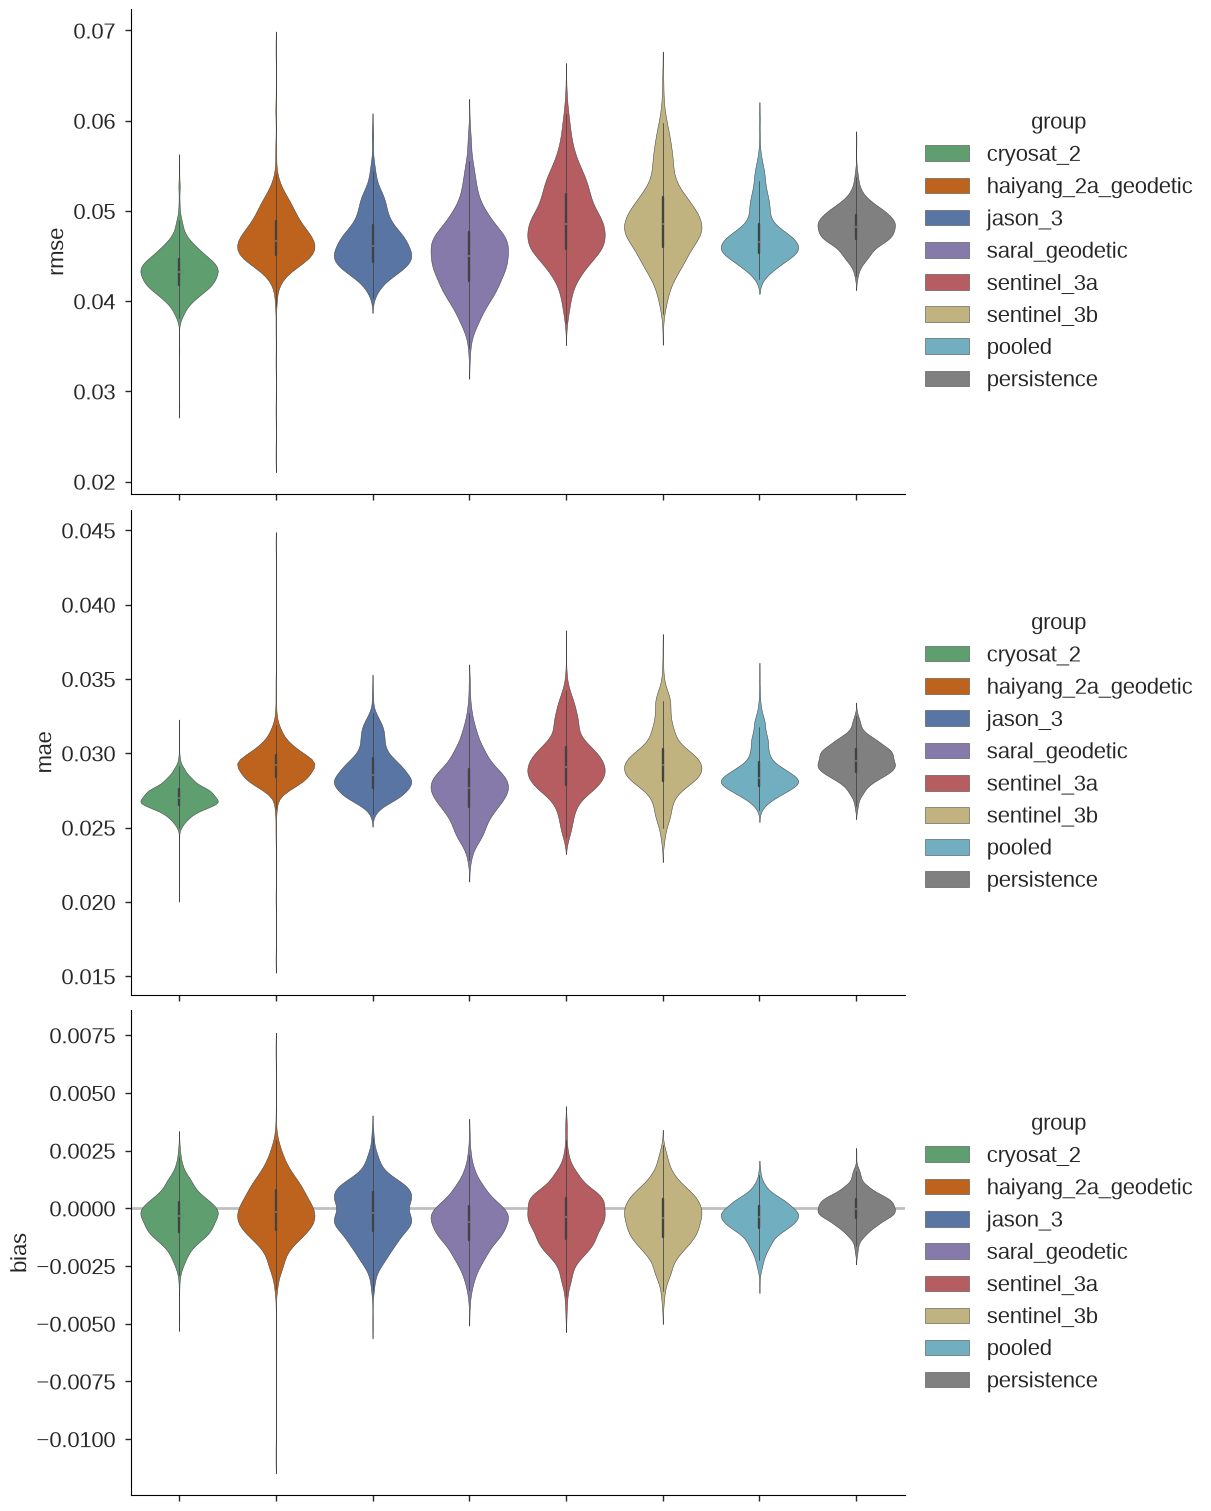

In [6]:
metrics = ["rmse", "mae", "bias"]
nrows = len(metrics)
ncols = 1
fig, axs = plt.subplots(nrows, ncols, figsize=(ncols*12, nrows*5), sharex=True)

p2 = persistence.expand_dims({"group": ["persistence"]})
combined = xr.concat([ads, p2], dim="group", join="exact", coords="minimal", compat="override")
palette = {label: "gray" if label == "persistence" else f"C{i}" for i, label in enumerate(combined["group"].values)}

for metric, ax in zip(metrics, axs):
    df = combined[metric].to_dataset().to_dataframe().reindex()
    sns.violinplot(
        df,
        x="group",
        y=metric,
        hue="group",
        legend=True,
        ax=ax,
        palette=palette,
    )
    sns.move_legend(ax, "center left", bbox_to_anchor=(1, .5), frameon=False)
    ax.set(xticklabels=[], xlabel="");
    if metric == "bias":
        ax.axhline(y=0, zorder=0, alpha=.5, color="gray")
fig.savefig(f"{fig_dir}/metrics.by_group.jpeg", dpi=300, bbox_inches="tight")

## Observed at input

In [7]:
ods = xr.open_dataset("runs/v0.10k/inference-validation/metrics/sla.seen_at_hour.nc", chunks="auto")
ods = ods.squeeze()
ods.load();

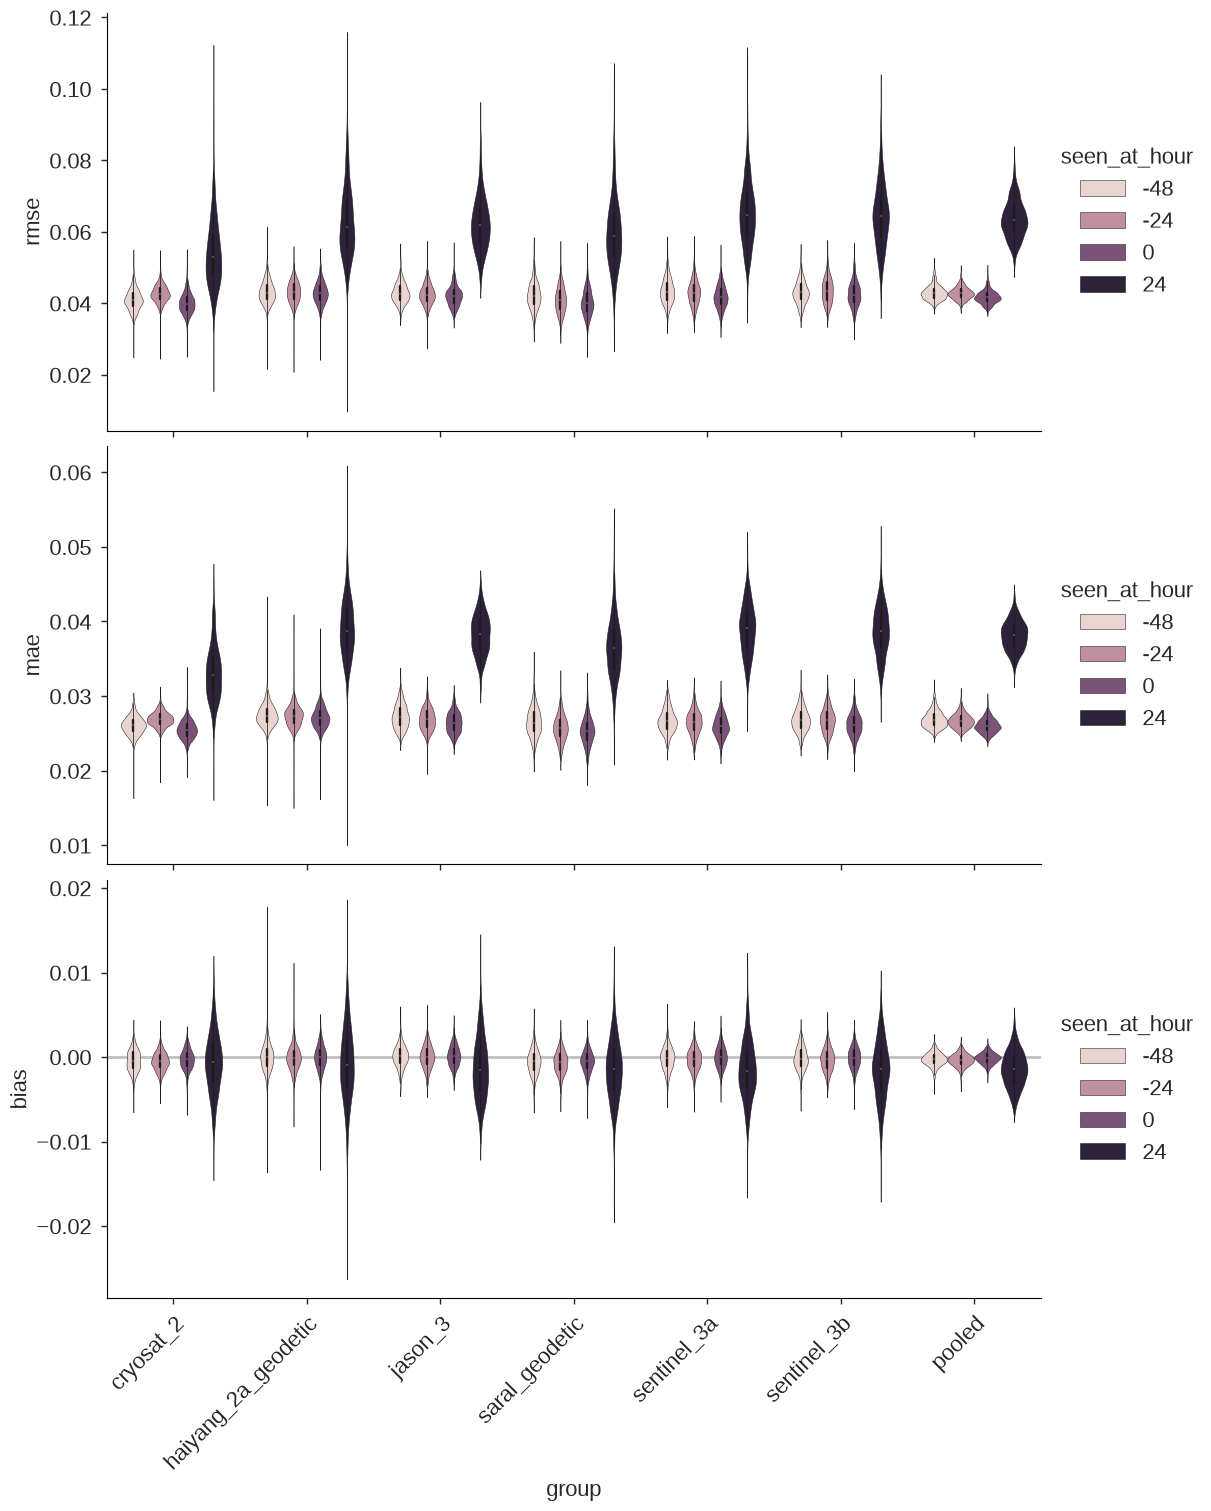

In [8]:
metrics = ["rmse", "mae", "bias"]
nrows = len(metrics)
ncols = 1
fig, axs = plt.subplots(nrows, ncols, figsize=(ncols*12, nrows*5), sharex=True)

for metric, ax in zip(metrics, axs):
    df = ods[metric].to_dataset().to_dataframe().reindex()
    sns.violinplot(
        df,
        x="group",
        y=metric,
        hue="seen_at_hour",
        legend=True,
        ax=ax,
    )
    sns.move_legend(ax, "center left", bbox_to_anchor=(1, .5), frameon=False)
    plt.xticks(rotation=45, ha='right', rotation_mode='anchor') 
    #ax.set_xticklabels(ax.get_xticklabels, 
    #ax.set(xticklabels=[], xlabel="");
    if metric == "bias":
        ax.axhline(y=0, zorder=0, alpha=.5, color="gray")
fig.savefig(f"{fig_dir}/metrics.by_group.seen_at.jpeg", dpi=300, bbox_inches="tight")

Focus on the group obs-count-weighted average, compare to persistence

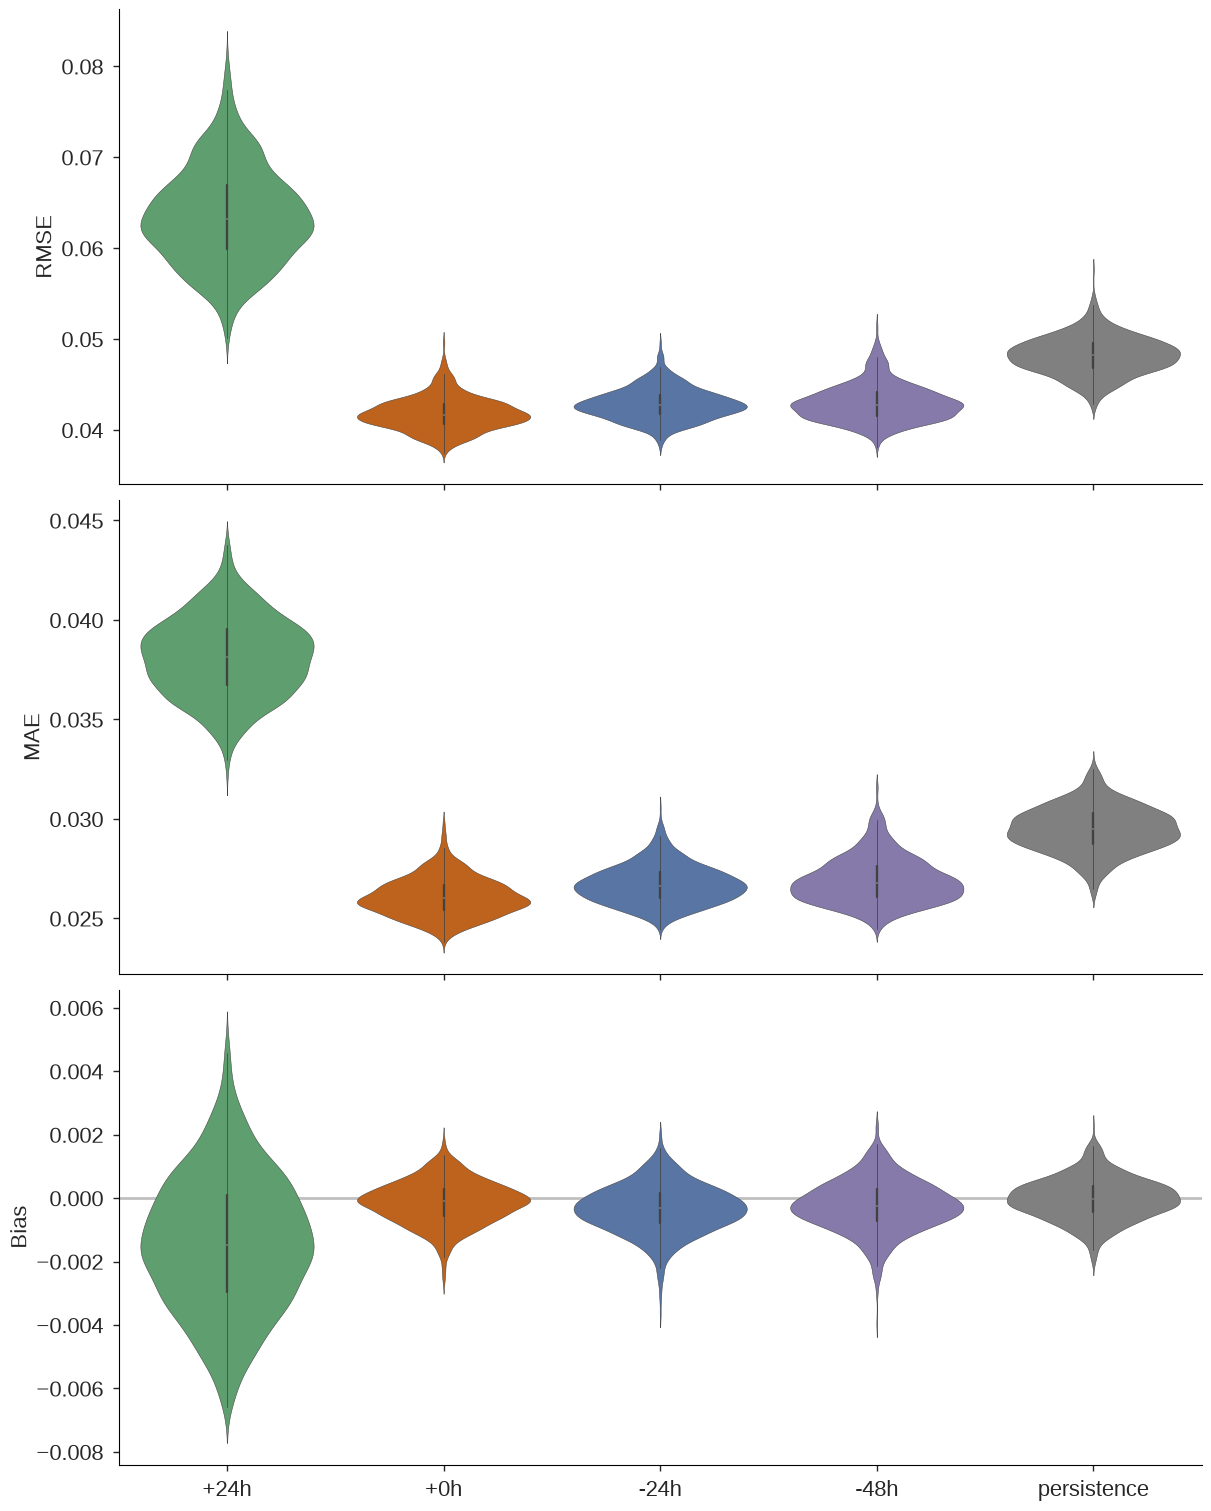

In [9]:
metrics = ["rmse", "mae", "bias"]
fig, axs = plt.subplots(len(metrics), 1, figsize=(12, len(metrics)*5), sharex=True)

model = ods[metrics].sel(group="pooled", drop=True)
model = model.assign_coords(seen_at_hour=[f"{h:+d}h" for h in model["seen_at_hour"].values])
p2 = persistence.expand_dims({"seen_at_hour": ["persistence"]})
combined = xr.concat([model, p2], dim="seen_at_hour", join="exact", coords="minimal", compat="override")

palette = {label: "gray" if label == "persistence" else f"C{i}" for i, label in enumerate(combined["seen_at_hour"].values)}
for metric, ax in zip(metrics, axs):
    sns.violinplot(
        combined[metric].to_dataframe().reset_index(),
        x="seen_at_hour",
        y=metric,
        hue="seen_at_hour",
        palette=palette,
        legend=False,
        ax=ax,
    )
    ax.set(xlabel="", ylabel=metric.upper() if metric != "bias" else metric.capitalize())
    if metric == "bias":
        ax.axhline(y=0, zorder=0, alpha=.5, color="gray")

fig.savefig(f"{fig_dir}/metrics.seen_at.jpeg", dpi=300, bbox_inches="tight")

## Look at overlap degree

In [10]:
ods = xr.open_dataset("runs/v0.10k/inference-validation/metrics/sla.overlap.nc", chunks="auto")
ods = ods.squeeze()
ods.load();

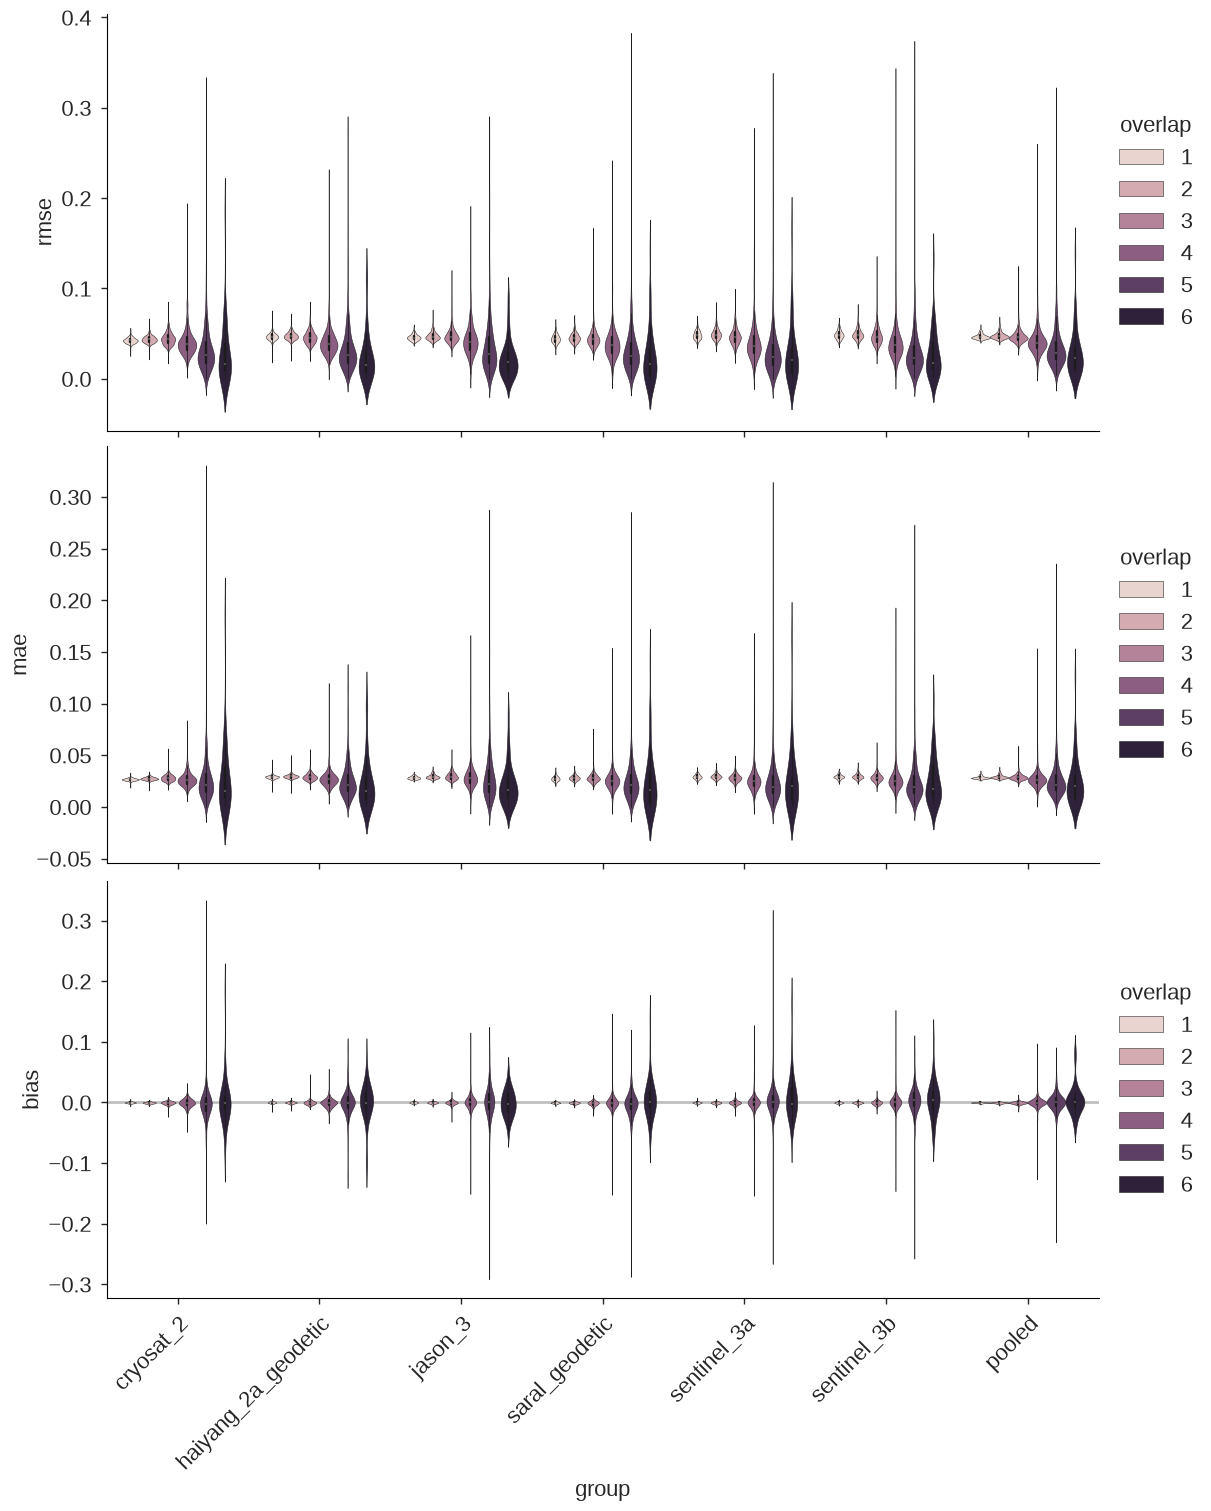

In [11]:
metrics = ["rmse", "mae", "bias"]
nrows = len(metrics)
ncols = 1
fig, axs = plt.subplots(nrows, ncols, figsize=(ncols*12, nrows*5), sharex=True)
for metric, ax in zip(metrics, axs):
    df = ods[metric].to_dataset().to_dataframe().reindex()
    sns.violinplot(
        df,
        x="group",
        y=metric,
        hue="overlap",
        legend=True,
        ax=ax,
    )
    sns.move_legend(ax, "center left", bbox_to_anchor=(1, .5), frameon=False)
    plt.xticks(rotation=45, ha='right', rotation_mode='anchor') 
    #ax.set_xticklabels(ax.get_xticklabels, 
    #ax.set(xticklabels=[], xlabel="");
    if metric == "bias":
        ax.axhline(y=0, zorder=0, alpha=.5, color="gray")

fig.savefig(f"{fig_dir}/metrics.by_group.overlap.jpeg", dpi=300, bbox_inches="tight")

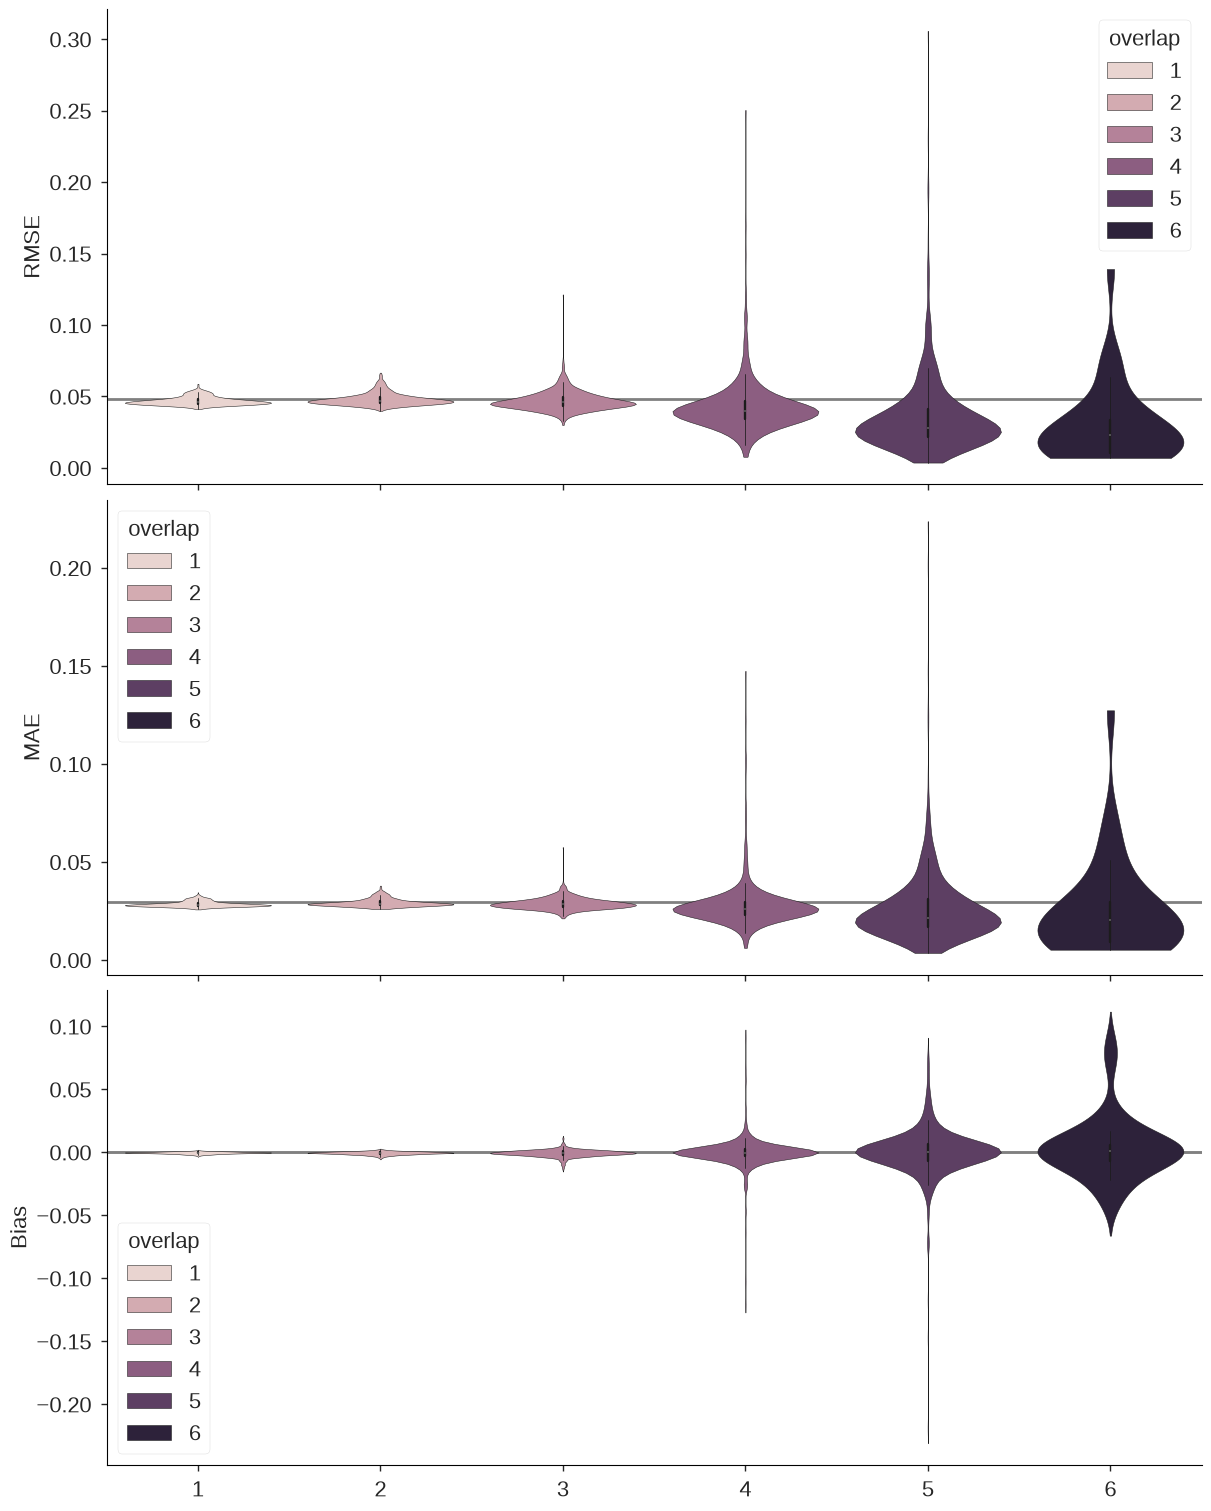

In [12]:
metrics = ["rmse", "mae", "bias"]
fig, axs = plt.subplots(len(metrics), 1, figsize=(12, len(metrics)*5), sharex=True)

for metric, ax in zip(metrics, axs):
    sns.violinplot(
        ods[metric].sel(group="pooled", drop=True).to_dataframe().reset_index(),
        x="overlap",
        y=metric,
        hue="overlap",
        legend=True,
        cut=0 if metric != "bias" else 2,
        ax=ax,
    )
    ax.set(xlabel="", ylabel=metric.upper() if metric != "bias" else metric.capitalize())
    if metric == "bias":
        ax.axhline(y=0, zorder=0, alpha=.5, color="gray")
    ax.axhline(y=pds[metric].sel(group="pooled", source="pooled").mean().values, color="gray", zorder=0)
    
fig.savefig(f"{fig_dir}/metrics.overlap.jpeg", dpi=300, bbox_inches="tight")